# FedRPCA vs Baselines on EuroSAT with CLIP ViT-B/32 (Kaggle-ready)

This notebook validates FedRPCA on the EuroSAT (RGB, 10 classes) vision task.
- Backbone: CLIP ViT-B/32 (frozen), fine-tune only a linear LoRA head
- Client partitioning: Dirichlet(α) non-IID on the training set; shared test set
- Aggregation methods: FedAvg / Task Arithmetic / TIES-Merging / FedRPCA (RPCA via Variable Projection)
- Output: global test accuracy per round; save CSV/PNG results

References:
- EuroSAT: Helber et al., IEEE JSTARS 2019.
- CLIP: Radford et al., ICML 2021.


In [ ]:
# Imports
import os
import math
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from PIL import Image
from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# =============== CLIP ViT-B/32 loading (open_clip -> clip -> transformers fallback) ===============
_preprocess = None
_backbone = None


def get_clip_preprocess():
    global _preprocess, _backbone
    if _preprocess is not None and _backbone is not None:
        return _backbone, _preprocess
    # prefer open_clip
    try:
        import open_clip
        model, _, preprocess = open_clip.create_model_and_transforms(
            'ViT-B-32', pretrained='laion2b_s34b_b79k')
        model.eval().to(DEVICE)
        _preprocess = preprocess
        _backbone = model
        return _backbone, _preprocess
    except Exception:
        pass
    # fallback to OpenAI clip
    try:
        import clip
        model, preprocess = clip.load('ViT-B/32', device=DEVICE)
        model.eval()
        _preprocess = preprocess
        _backbone = model
        return _backbone, _preprocess
    except Exception:
        pass
    # fallback to transformers
    try:
        from transformers import CLIPModel, CLIPProcessor
        model = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(DEVICE)
        processor = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')
        model.eval()
        def preprocess(img):
            inputs = processor(images=img, return_tensors='pt')
            return inputs
        _preprocess = preprocess
        _backbone = model
        return _backbone, _preprocess
    except Exception as e:
        raise RuntimeError('Failed to load CLIP ViT-B/32') from e


@torch.no_grad()
def encode_images(pil_images) -> torch.Tensor:
    model, preprocess = get_clip_preprocess()
    # open_clip / clip normal path; transformers handled differently
    try:
        import open_clip  # noqa: F401
        batch = torch.stack([preprocess(img) for img in pil_images]).to(DEVICE)
        feats = model.encode_image(batch)
    except Exception:
        try:
            import clip  # noqa: F401
            batch = torch.stack([preprocess(img) for img in pil_images]).to(DEVICE)
            feats = model.encode_image(batch)
        except Exception:
            proc = [preprocess(img) for img in pil_images]
            pixel_values = torch.cat([p['pixel_values'] for p in proc], dim=0).to(DEVICE)
            outputs = model.get_image_features(pixel_values=pixel_values)
            feats = outputs
    feats = feats / (feats.norm(dim=-1, keepdim=True) + 1e-12)
    return feats.float()

# =============== EuroSAT path collection (Kaggle inputs / local / torchvision download) ===============

def load_eurosat_paths(limit_per_class=None):
    kaggle_roots = [
        Path('/kaggle/input/eurosat-rgb/euroSAT_RGB/2750'),
        Path('/kaggle/input/eurosat/2750'),
        Path('/kaggle/input/eurosat-rgb/2750'),
        Path('/kaggle/input/EuroSAT/2750'),
    ]
    for root in kaggle_roots:
        if root.exists():
            classes = sorted([p.name for p in root.iterdir() if p.is_dir()])
            img_paths, labels = [], []
            for ci, cname in enumerate(classes):
                imgs = sorted((root / cname).glob('*.jpg'))
                if limit_per_class is not None:
                    imgs = imgs[:limit_per_class]
                for p in imgs:
                    img_paths.append(p)
                    labels.append(ci)
            return img_paths, np.array(labels, dtype=np.int64), classes
    local_root = Path('./EuroSAT/2750')
    if local_root.exists():
        classes = sorted([p.name for p in local_root.iterdir() if p.is_dir()])
        img_paths, labels = [], []
        for ci, cname in enumerate(classes):
            imgs = sorted((local_root / cname).glob('*.jpg'))
            if limit_per_class is not None:
                imgs = imgs[:limit_per_class]
            for p in imgs:
                img_paths.append(p)
                labels.append(ci)
        return img_paths, np.array(labels, dtype=np.int64), classes
    try:
        from torchvision.datasets import EuroSAT
        data_root = Path('./data_eurosat')
        data_root.mkdir(parents=True, exist_ok=True)
        ds = EuroSAT(root=str(data_root), download=True)
        classes = list(ds.classes)
        all_paths = [Path(p) for p, _ in ds.imgs]
        all_labels = np.array([t for _, t in ds.imgs], dtype=np.int64)
        if limit_per_class is not None:
            selected_idx = []
            for ci in range(len(classes)):
                ci_idx = np.where(all_labels == ci)[0][:limit_per_class]
                selected_idx.append(ci_idx)
            selected_idx = np.concatenate(selected_idx, axis=0)
            all_paths = [all_paths[i] for i in selected_idx]
            all_labels = all_labels[selected_idx]
        return all_paths, all_labels, classes
    except Exception:
        pass
    raise RuntimeError('EuroSAT dataset not found; provide Kaggle input or local directory, or allow torchvision to download.')

# =============== Utilities: Dirichlet split, feature precompute, dataset wrapper ===============

def dirichlet_split_noniid(labels, num_clients, alpha):
    labels = np.array(labels)
    num_classes = int(labels.max() + 1)
    idx_by_class = [np.where(labels == c)[0] for c in range(num_classes)]
    client_indices = [[] for _ in range(num_clients)]
    for c in range(num_classes):
        idx_c = idx_by_class[c]
        np.random.shuffle(idx_c)
        proportions = np.random.dirichlet(alpha * np.ones(num_clients))
        splits = (np.cumsum(proportions) * len(idx_c)).astype(int)
        prev = 0
        for i, s in enumerate(splits):
            client_indices[i].extend(idx_c[prev:s].tolist())
            prev = s
    return [np.array(sorted(idxs)) for idxs in client_indices]

class ArrayDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], int(self.y[idx])

@torch.no_grad()
def precompute_features(paths, batch_size=128):
    feats = []
    for i in range(0, len(paths), batch_size):
        imgs = [Image.open(p).convert('RGB') for p in paths[i:i+batch_size]]
        f = encode_images(imgs).cpu()
        feats.append(f)
    feats = torch.cat(feats, dim=0)
    return feats.numpy().astype(np.float32)

# =============== Build/cache CLIP features of EuroSAT and create client loaders ===============
CACHE_PATH = './eurosat_clip_features.npz'

@torch.no_grad()
def get_or_build_features(test_size=0.2, limit_per_class=None, force_recompute=False):
    if (not force_recompute) and os.path.exists(CACHE_PATH):
        data = np.load(CACHE_PATH, allow_pickle=True)
        X_train, y_train, X_test, y_test, classes = data['X_train'], data['y_train'], data['X_test'], data['y_test'], list(data['classes'])
    else:
        paths, labels, classes = load_eurosat_paths(limit_per_class=limit_per_class)
        idx = np.arange(len(paths))
        X_train_idx, X_test_idx, y_train, y_test = train_test_split(
            idx, labels, test_size=test_size, random_state=SEED, stratify=labels)
        paths_train = [paths[i] for i in X_train_idx]
        paths_test = [paths[i] for i in X_test_idx]
        X_train = precompute_features(paths_train, batch_size=128)
        X_test = precompute_features(paths_test, batch_size=128)
        np.savez(CACHE_PATH, X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test, classes=np.array(classes, dtype=object))
    # Feature standardization (based on training set statistics)
    mu = X_train.mean(axis=0, keepdims=True)
    sigma = X_train.std(axis=0, keepdims=True) + 1e-6
    X_train = (X_train - mu) / sigma
    X_test = (X_test - mu) / sigma
    return X_train.astype(np.float32), y_train, X_test.astype(np.float32), y_test, classes

# Load or build features
X_train, y_train, X_test, y_test, classes = get_or_build_features(test_size=0.2, limit_per_class=None)
num_classes = int(max(y_train.max(), y_test.max()) + 1)
feature_dim = X_train.shape[1]



def make_client_loaders(num_clients=20, alpha=0.3, batch_size=64):
    splits = dirichlet_split_noniid(y_train, num_clients, alpha)
    loaders = []
    for idxs in splits:
        ds = ArrayDataset(X_train[idxs], y_train[idxs])
        loaders.append(DataLoader(ds, batch_size=batch_size, shuffle=True, num_workers=0))
    test_ds = ArrayDataset(X_test, y_test)
    test_loader = DataLoader(test_ds, batch_size=512, shuffle=False, num_workers=0)
    return loaders, test_loader



In [ ]:
# Lightweight model + LoRA (applies only to classification head)
class LoRALinearHead(nn.Module):
    def __init__(self, in_features: int, out_features: int, rank: int = 4, alpha: float = 1.0):
        super().__init__()
        self.in_features = in_features
        self.out_features = out_features
        self.rank = rank
        self.alpha = alpha
        self.scale = alpha / max(1, rank)
        
        # Frozen base weight (can be set to 0 to simulate LoRA-only)
        self.weight = nn.Parameter(torch.zeros(out_features, in_features), requires_grad=False)
        self.bias = nn.Parameter(torch.zeros(out_features), requires_grad=True)  # trainable bias
        
        # LoRA parameters A(in, r), B(r, out)
        self.lora_A = nn.Parameter(torch.randn(in_features, rank) * 0.01)
        self.lora_B = nn.Parameter(torch.zeros(rank, out_features))
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [batch, in_features]
        base = F.linear(x, self.weight, self.bias)  # add bias only
        lora = (x @ self.lora_A) @ self.lora_B  # [batch, out]
        return base + self.scale * lora

class ImageClassifierLoRA(nn.Module):
    def __init__(self, in_features: int, num_classes: int, rank: int = 4, alpha: float = 1.0):
        super().__init__()
        self.head = LoRALinearHead(in_features, num_classes, rank=rank, alpha=alpha)
    def forward(self, x):
        return self.head(x)

# LoRA weight vectorization/application

def get_lora_vector(model: ImageClassifierLoRA) -> np.ndarray:
    A = model.head.lora_A.detach().cpu().numpy().ravel()
    B = model.head.lora_B.detach().cpu().numpy().ravel()
    b = model.head.bias.detach().cpu().numpy().ravel()
    return np.concatenate([A, B, b])


def set_lora_vector(model: ImageClassifierLoRA, vec: np.ndarray):
    in_f, out_f, r = model.head.in_features, model.head.out_features, model.head.rank
    a_size = in_f * r
    b_size = r * out_f
    A = vec[:a_size].reshape(in_f, r)
    B = vec[a_size:a_size+b_size].reshape(r, out_f)
    bias = vec[a_size+b_size:a_size+b_size+out_f].reshape(out_f)
    with torch.no_grad():
        model.head.lora_A.copy_(torch.from_numpy(A).to(model.head.lora_A.dtype))
        model.head.lora_B.copy_(torch.from_numpy(B).to(model.head.lora_B.dtype))
        model.head.bias.copy_(torch.from_numpy(bias).to(model.head.bias.dtype))


def delta_between(new_vec: np.ndarray, old_vec: np.ndarray) -> np.ndarray:
    return new_vec - old_vec


def apply_delta(vec: np.ndarray, delta: np.ndarray, scale: float = 1.0) -> np.ndarray:
    return vec + scale * delta

# Initialize global model
rank_lora = 4
model_global = ImageClassifierLoRA(feature_dim, num_classes, rank=rank_lora, alpha=1.0)
model_global


ImageClassifierLoRA(
  (head): LoRALinearHead()
)

In [ ]:
# RPCA via Variable Projection (full robust version)
import numpy.linalg as npla

def soft_threshold(X: np.ndarray, kappa: float) -> np.ndarray:
    return np.sign(X) * np.maximum(np.abs(X) - kappa, 0.0)

def truncated_svd_rank_r(M: np.ndarray, rank: int):
    U, s, Vt = npla.svd(M, full_matrices=False)
    r = min(rank, len(s))
    return U[:, :r], s[:r], Vt[:r, :]

def _robust_scale_rows(X: np.ndarray):
    row_med = np.median(X, axis=1, keepdims=True)
    mad = np.median(np.abs(X - row_med), axis=1, keepdims=True)
    mad = np.where(mad < 1e-8, 1e-8, mad)
    Xn = (X - row_med) / mad
    return Xn, row_med, mad

def _clean_matrix(X: np.ndarray, clip_q: float = 0.999):
    Xc = X.copy()
    d, n = Xc.shape
    for i in range(d):
        row = Xc[i]
        lo = np.quantile(row, 1.0 - clip_q) if n > 1 else row.min()
        hi = np.quantile(row, clip_q) if n > 1 else row.max()
        if np.isfinite(lo) and np.isfinite(hi):
            Xc[i] = np.clip(row, lo, hi)
    Xc[~np.isfinite(Xc)] = 0.0
    return Xc

def _svd_soft_rpca(X: np.ndarray, tau: float):
    U, s, Vt = npla.svd(X, full_matrices=False)
    s_shrink = np.maximum(s - tau, 0.0)
    L = (U * s_shrink) @ Vt
    S = X - L
    return L, S

def robust_rpca_vp(X: np.ndarray, rank: int, kappa: float | None = None,
                   max_iter: int = 200, tol: float = 1e-6, continuation: bool = True,
                   kappa_mult: float = 1.0, max_restarts: int = 1, verbose: bool = False):
    # Preprocess: cleaning + row robust scaling
    Xc = _clean_matrix(X)
    Xn, row_med, mad = _robust_scale_rows(Xc)
    d, n = Xn.shape
    # Adaptive kappa
    if kappa is None:
        base = np.median(np.abs(Xn))
        kappa = 0.8 * base if base > 0 else 1e-3
    kappa = float(kappa) * float(kappa_mult)

    best = None
    for restart in range(max_restarts):
        L = np.zeros_like(Xn)
        S = np.zeros_like(Xn)
        prev_obj = np.inf
        kappa_now = kappa * (3.0 if continuation else 1.0)
        for it in range(max_iter):
            # S-step
            S = soft_threshold(Xn - L, kappa_now)
            # L-step
            try:
                U, s, Vt = truncated_svd_rank_r(Xn - S, rank)
                L = (U * s) @ Vt
            except Exception:
                # Fallback: nuclear-norm soft-thresholding
                L, S_alt = _svd_soft_rpca(Xn, tau=kappa_now)
                # S is still obtained by soft-thresholding
            resid = Xn - L - S
            obj = 0.5 * np.sum(resid * resid) + kappa_now * np.sum(np.abs(S))
            if verbose and (it % 10 == 0):
                print(f'[RPCA-VP] r={restart} it={it} obj={obj:.6e} kn={kappa_now:.3e}')
            if abs(prev_obj - obj) / (prev_obj + 1e-12) < tol:
                break
            prev_obj = obj
            # Continuation: gradually decrease kappa to improve sparsity accuracy
            if continuation:
                kappa_now = max(kappa, 0.9 * kappa_now)
        # De-normalize
        L_denorm = L * mad + row_med
        S_denorm = S * mad
        resid0 = Xc - L_denorm - S_denorm
        obj0 = 0.5 * np.sum(resid0 * resid0) + kappa * np.sum(np.abs(S_denorm))
        if (best is None) or (obj0 < best[0]):
            best = (obj0, L_denorm, S_denorm)
    _, L_best, S_best = best
    # Final cleanup
    L_best[~np.isfinite(L_best)] = 0.0
    S_best[~np.isfinite(S_best)] = 0.0
    return L_best, S_best


In [ ]:
# Four aggregators: FedAvg / Task Arithmetic / full FedRPCA / TIES-Merging

def fedavg_aggregate(deltas: list[np.ndarray]) -> np.ndarray:
    return np.mean(np.stack(deltas, axis=1), axis=1)

def task_arithmetic_aggregate(deltas: list[np.ndarray], beta: float = 1.0) -> np.ndarray:
    avg = np.mean(np.stack(deltas, axis=1), axis=1)
    return beta * avg

def _adaptive_beta_sparse(S: np.ndarray) -> float:
    # Adaptive scaling based on sparsity
    sparsity = np.mean(np.isclose(S, 0.0))
    return float(max(0.2, min(0.8, 1.0 - 0.5 * sparsity)))

def _clip_norm(vec: np.ndarray, max_norm: float = 5.0) -> np.ndarray:
    n = npla.norm(vec) + 1e-12
    if n > max_norm:
        return vec * (max_norm / n)
    return vec

def fedrpca_aggregate(deltas: list[np.ndarray], rank: int = 2, kappa: float | None = None,
                      beta_sparse: float | None = None, clip_norm_val: float = 10.0) -> np.ndarray:
    X = np.stack(deltas, axis=1)  # (d, n)
    # Cleaning + robust scaling
    Xc = _clean_matrix(X)
    Xn, row_med, mad = _robust_scale_rows(Xc)
    # Full RPCA-VP
    Ln, Sn = robust_rpca_vp(Xn, rank=rank, kappa=kappa, max_iter=200, tol=1e-6, continuation=True)
    # De-standardize
    L = Ln * mad + row_med
    S = Sn * mad
    # Adaptive coefficient for sparse part
    if beta_sparse is None:
        beta_sparse = _adaptive_beta_sparse(S)
    # Combine
    L_mean = np.mean(L, axis=1)
    S_mean = np.mean(S, axis=1)
    agg = L_mean + float(beta_sparse) * S_mean
    # Aggregation clipping
    agg = _clip_norm(agg, max_norm=clip_norm_val)
    return agg

def ties_merging_aggregate(deltas: list[np.ndarray], prune_q: float = 0.6, clip_norm_val: float = 10.0) -> np.ndarray:
    """TIES-Merging:
    1) For each client update vector, prune by magnitude quantile (keep large magnitudes);
    2) For each parameter dimension, compare total magnitude of positive vs negative sides,
       keep the side with larger total magnitude and zero-out the other;
    3) Average remaining updates and apply norm clipping.
    """
    X = np.stack(deltas, axis=1)  # (d, n)
    d, n = X.shape
    Xp = X.copy()
    # Step 1: column-wise pruning (each client keeps larger-magnitude coordinates)
    if 0.0 < prune_q < 1.0:
        for c in range(n):
            thr = np.quantile(np.abs(Xp[:, c]), prune_q)
            Xp[np.abs(Xp[:, c]) < thr, c] = 0.0
    # Step 2: resolve sign conflicts row-wise (keep dominant sign per dimension)
    pos_sum = np.sum(np.where(Xp > 0.0, Xp, 0.0), axis=1)
    neg_sum = np.sum(np.where(Xp < 0.0, -Xp, 0.0), axis=1)
    keep_pos = pos_sum >= neg_sum
    Xc = Xp.copy()
    Xc[(keep_pos)[:, None] & (Xc < 0.0)] = 0.0
    Xc[(~keep_pos)[:, None] & (Xc > 0.0)] = 0.0
    # Step 3: average + clip
    agg = np.mean(Xc, axis=1)
    agg = _clip_norm(agg, max_norm=clip_norm_val)
    return agg


In [ ]:
# Client local training and evaluation (EuroSAT + CLIP features)

def client_train_epoch(model: ImageClassifierLoRA, loader: DataLoader, lr: float = 5e-3, device: str = DEVICE):
    model.train()
    model.to(device)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)
        logits = model(xb)
        loss = F.cross_entropy(logits, yb)
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        opt.step()

@torch.no_grad()
def evaluate(model: ImageClassifierLoRA, loader: DataLoader, device: str = DEVICE) -> float:
    model.eval()
    model.to(device)
    correct = 0
    total = 0
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)
        logits = model(xb)
        pred = logits.argmax(dim=1)
        correct += (pred == yb).sum().item()
        total += len(yb)
    return correct / max(1, total)


In [ ]:
# Federated training main loop (EuroSAT + CLIP features)
import matplotlib.pyplot as plt


def run_federated(rounds=5, clients=10, local_epochs=3, lr=5e-3, alpha=0.3,
                  agg_method='fedrpca', rank=4, task_beta=2.0, rpca_kappa=None,
                  device=DEVICE, batch_size=64):
    loaders, test_loader = make_client_loaders(num_clients=clients, alpha=alpha, batch_size=batch_size)
    global_model = ImageClassifierLoRA(feature_dim, num_classes, rank=rank_lora, alpha=1.0)
    global_vec = get_lora_vector(global_model)
    acc_hist = []
    for r in range(rounds):
        deltas = []
        for cid in range(clients):
            local = ImageClassifierLoRA(feature_dim, num_classes, rank=rank_lora, alpha=1.0)
            set_lora_vector(local, global_vec.copy())
            for _ in range(local_epochs):
                client_train_epoch(local, loaders[cid], lr=lr, device=device)
            new_vec = get_lora_vector(local)
            deltas.append(delta_between(new_vec, global_vec))
        if agg_method == 'fedavg':
            agg = fedavg_aggregate(deltas)
        elif agg_method == 'task':
            agg = task_arithmetic_aggregate(deltas, beta=task_beta)
        elif agg_method == 'ties':
            agg = ties_merging_aggregate(deltas)
        else:
            agg = fedrpca_aggregate(deltas, rank=rank, kappa=rpca_kappa, beta_sparse=0.5)
        global_vec = apply_delta(global_vec, agg, scale=1.0)
        set_lora_vector(global_model, global_vec)
        acc = evaluate(global_model, test_loader, device=device)
        acc_hist.append(acc)
        print(f'Round {r+1}/{rounds} | {agg_method} | Acc={acc:.4f}')
    return acc_hist



Round 1/25 | fedavg | Acc=0.5750
Round 2/25 | fedavg | Acc=0.8239
Round 3/25 | fedavg | Acc=0.8648
Round 4/25 | fedavg | Acc=0.8778
Round 5/25 | fedavg | Acc=0.8898
Round 6/25 | fedavg | Acc=0.8944
Round 7/25 | fedavg | Acc=0.9002
Round 8/25 | fedavg | Acc=0.8994
Round 9/25 | fedavg | Acc=0.9007
Round 10/25 | fedavg | Acc=0.9043
Round 11/25 | fedavg | Acc=0.9065
Round 12/25 | fedavg | Acc=0.9080
Round 13/25 | fedavg | Acc=0.9096
Round 14/25 | fedavg | Acc=0.9107
Round 15/25 | fedavg | Acc=0.9091
Round 16/25 | fedavg | Acc=0.9080
Round 17/25 | fedavg | Acc=0.9085
Round 18/25 | fedavg | Acc=0.9089
Round 19/25 | fedavg | Acc=0.9083
Round 20/25 | fedavg | Acc=0.9093
Round 21/25 | fedavg | Acc=0.9076
Round 22/25 | fedavg | Acc=0.9080
Round 23/25 | fedavg | Acc=0.9072
Round 24/25 | fedavg | Acc=0.9072
Round 25/25 | fedavg | Acc=0.9076
Round 1/25 | task | Acc=0.7285
Round 2/25 | task | Acc=0.7620
Round 3/25 | task | Acc=0.8259
Round 4/25 | task | Acc=0.7991
Round 5/25 | task | Acc=0.8420
Roun

/tmp/ipykernel_13/1233468271.py:72: RuntimeWarning: invalid value encountered in scalar divide
  if abs(prev_obj - obj) / (prev_obj + 1e-12) < tol:


Round 1/25 | fedrpca | Acc=0.4957
Round 2/25 | fedrpca | Acc=0.8015
Round 3/25 | fedrpca | Acc=0.8687
Round 4/25 | fedrpca | Acc=0.8854
Round 5/25 | fedrpca | Acc=0.8959
Round 6/25 | fedrpca | Acc=0.9009
Round 7/25 | fedrpca | Acc=0.9072
Round 8/25 | fedrpca | Acc=0.9104
Round 9/25 | fedrpca | Acc=0.9119
Round 10/25 | fedrpca | Acc=0.9148
Round 11/25 | fedrpca | Acc=0.9157
Round 12/25 | fedrpca | Acc=0.9178
Round 13/25 | fedrpca | Acc=0.9183
Round 14/25 | fedrpca | Acc=0.9181
Round 15/25 | fedrpca | Acc=0.9207
Round 16/25 | fedrpca | Acc=0.9211
Round 17/25 | fedrpca | Acc=0.9224
Round 18/25 | fedrpca | Acc=0.9207
Round 19/25 | fedrpca | Acc=0.9207
Round 20/25 | fedrpca | Acc=0.9220
Round 21/25 | fedrpca | Acc=0.9204
Round 22/25 | fedrpca | Acc=0.9241
Round 23/25 | fedrpca | Acc=0.9226
Round 24/25 | fedrpca | Acc=0.9220
Round 25/25 | fedrpca | Acc=0.9217
保存CSV: eurosat_clip_compare_20250903_095255.csv
保存图: eurosat_clip_compare_20250903_095255.png


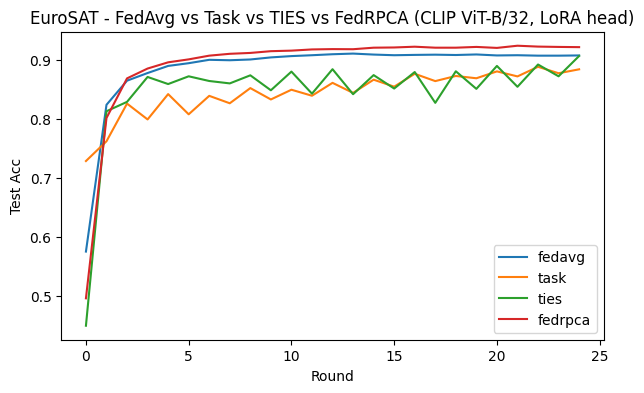

In [ ]:
# full run: EuroSAT + save results
import pandas as pd
from datetime import datetime

RUN_ROUNDS = 25
RUN_CLIENTS = 20
LOCAL_EPOCHS = 16
LR = 5e-3
ALPHA = 0.3
RANK_RPCA = 4
TASK_BETA = 2.0

stamp = datetime.now().strftime('%Y%m%d_%H%M%S')
results = {}
for m in ['fedavg','task','ties','fedrpca']:
    acc = run_federated(rounds=RUN_ROUNDS, clients=RUN_CLIENTS, local_epochs=LOCAL_EPOCHS,
                        lr=LR, alpha=ALPHA, agg_method=m, rank=RANK_RPCA, task_beta=TASK_BETA,
                        device=DEVICE, batch_size=64)
    results[m] = acc

# Save CSV
rows = []
for m, acc in results.items():
    for r, v in enumerate(acc, start=1):
        rows.append({'method': m, 'round': r, 'acc': v})

df = pd.DataFrame(rows)
csv_path = f'eurosat_clip_compare_{stamp}.csv'
df.to_csv(csv_path, index=False)
print('Saved CSV:', csv_path)

# Save figure
plt.figure(figsize=(7,4))
for m, acc in results.items():
    plt.plot(acc, label=m)
plt.xlabel('Round')
plt.ylabel('Test Acc')
plt.legend()
plt.title('EuroSAT - FedAvg vs Task vs TIES vs FedRPCA (CLIP ViT-B/32, LoRA head)')
png_path = f'eurosat_clip_compare_{stamp}.png'
plt.savefig(png_path, dpi=150, bbox_inches='tight')
print('Saved figure:', png_path)
